# 01 · Exploratory Data Analysis: MSME Financial Health

**Goal:** understand the 50,000-business dataset before building anything.

Questions this notebook answers:
1. Is the data clean? What is missing, and why?
2. What do the supplied answer columns (scores, PD, risk band, limit) look like, and **how were they generated**?
3. Which business signals relate to default risk, and how strongly?
4. Are new-to-credit (NTC) businesses really riskier?
5. How do seasonality and industry shape risk?
6. Do the data sources (GST, bank, UPI, payroll) agree with each other?

Each section ends with a **takeaway** that feeds the feature and model design.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

from msme_health.config import DATA_PATH, PILLARS, NUMERIC_RAW, CATEGORICAL

sns.set_theme(style="whitegrid", palette="deep", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60, "display.width", 200)

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns · {df.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")
df.head(3).T

50,000 rows × 45 columns · 21.2 MB in memory


,0,1,2
MSME_ID,MSME0000001,MSME0000002,MSME0000003
Customer_Segment,NTC,NTB,NTC
Business_Type,LLP,LLP,Partnership
Industry,Logistics,Services,Textiles
Location_Category,Tier 2,Tier 1,Tier 3
Years_in_Operation,8.0,3.6,8.4
Employee_Count,2,5,1
Annual_Turnover_INR,5854430,14773394,1070209
Monthly_GST_Sales_INR,476042,991792,101178
Monthly_GST_Purchases_INR,327244,493131,74567


## 1. Column groups

The 45 columns fall into three groups:
- **ID + profile** (7): who the business is.
- **Behavioural inputs** (27 numeric): GST, UPI, bank, credit, payroll, invoices.
- **Answer columns** (11): 6 pillar scores, overall score, PD, risk band, eligibility, limit. These are the *targets*. They must never be used as inputs.

In [2]:
answer_cols = list(PILLARS) + ["Financial_Health_Score", "Probability_of_Default", "Credit_Risk_Category",
                               "Credit_Eligible", "Recommended_Credit_Limit_INR"]
groups = pd.Series({"ID": 1, "Profile / categorical": len(CATEGORICAL), "Numeric inputs": len(NUMERIC_RAW), "Answer columns": len(answer_cols)})
print(groups.to_string())
assert groups.sum() == df.shape[1]

ID                        1
Profile / categorical     6
Numeric inputs           27
Answer columns           11


## 2. Data quality

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
print("Duplicate IDs:", df.MSME_ID.duplicated().sum(), "· Duplicate rows:", df.drop(columns="MSME_ID").duplicated().sum())
quality[quality.missing > 0]

Duplicate IDs: 0 · Duplicate rows: 0


,dtype,missing,missing_%,unique
EMI_On_Time_Rate_Pct,float64,32556,65.11,288


Only `EMI_On_Time_Rate_Pct` has blanks. Is that random, or structural?

In [4]:
pd.crosstab(df.Has_Existing_Loan, df.EMI_On_Time_Rate_Pct.isna(), rownames=["Has loan"], colnames=["EMI rate missing"])

EMI rate missing,False,True
Has loan,,
No,0,32556
Yes,17444,0


**Takeaway:** the blanks are *structural*: EMI on-time rate is missing exactly when the business has no loan. We should **not** fill it with the median, which would invent a repayment record. LightGBM handles the blank natively. For the linear baseline we add a "missing" indicator.

### Logical consistency checks

In [5]:
checks = {
    "NTC businesses with credit history > 0": int(((df.Customer_Segment == "NTC") & (df.Credit_History_Months > 0)).sum()),
    "NTC businesses with an existing loan": int(((df.Customer_Segment == "NTC") & (df.Has_Existing_Loan == "Yes")).sum()),
    "Existing-to-Credit without a loan": int(((df.Customer_Segment == "Existing-to-Credit") & (df.Has_Existing_Loan == "No")).sum()),
    "No loan but EMI > 0": int(((df.Has_Existing_Loan == "No") & (df.Monthly_Loan_EMI_INR > 0)).sum()),
    "Credit history longer than business age": int((df.Credit_History_Months / 12 > df.Years_in_Operation).sum()),
    "UPI inflow > total bank credits": int((df.Monthly_UPI_Inflow_INR > df.Monthly_Bank_Credits_INR).sum()),
    "Percent columns outside 0-100": int(sum(((df[c] < 0) | (df[c] > 100)).sum() for c in df.columns if c.endswith("_Pct") and c != "Revenue_Growth_Rate_Pct")),
    "Negative money values": int(sum((df[c] < 0).sum() for c in df.columns if c.endswith("_INR"))),
}
pd.Series(checks, name="violations").to_frame()

,violations
NTC businesses with credit history > 0,0
NTC businesses with an existing loan,0
Existing-to-Credit without a loan,0
No loan but EMI > 0,0
Credit history longer than business age,0
UPI inflow > total bank credits,22
Percent columns outside 0-100,0
Negative money values,0


**Takeaway:** the data is internally consistent. Only 22 businesses report more UPI inflow than total bank credits, which is impossible in reality. We keep them but use this as an **anomaly rule**.

### Segment definitions (confirmed from data)

In [6]:
seg = df.groupby("Customer_Segment").agg(
    businesses=("MSME_ID", "size"),
    share=("MSME_ID", lambda s: len(s) / len(df)),
    with_loan=("Has_Existing_Loan", lambda s: (s == "Yes").mean()),
    median_credit_history_m=("Credit_History_Months", "median"),
    max_credit_history_m=("Credit_History_Months", "max"),
)
seg.style.format({"share": "{:.1%}", "with_loan": "{:.1%}"})

,businesses,share,with_loan,median_credit_history_m,max_credit_history_m
Customer_Segment,,,,,
Existing-to-Credit,13965,27.9%,100.0%,29.000000,180
NTB,14967,29.9%,23.2%,0.000000,180
NTC,21068,42.1%,0.0%,0.000000,0


- **NTC** (42%): no loan, no credit history. The bureau is empty, so alternate data is the only signal.
- **NTB** (30%): new to *this* lender; 23% have a loan elsewhere.
- **Existing-to-Credit** (28%): all have loans and a bureau history.

### 2b. Null count for every column

The table above only shows columns with blanks. Here is the full picture: every column, its null count and its null %.

In [7]:
nulls = pd.DataFrame({"null_count": df.isna().sum(), "null_%": (df.isna().mean() * 100).round(2)})
nulls["group"] = np.where(nulls.index == "MSME_ID", "ID", np.where(nulls.index.isin(CATEGORICAL), "categorical",
                          np.where(nulls.index.isin(answer_cols), "answer", "numeric input")))
print(f"Total cells: {df.size:,} · null cells: {df.isna().sum().sum():,} ({df.isna().sum().sum() / df.size:.2%})")
print(f"Columns with any null: {(nulls.null_count > 0).sum()} of {df.shape[1]}")
print(f"Rows with at least one null: {df.isna().any(axis=1).sum():,} ({df.isna().any(axis=1).mean():.1%})")
nulls.sort_values("null_count", ascending=False)

Total cells: 2,250,000 · null cells: 32,556 (1.45%)
Columns with any null: 1 of 45
Rows with at least one null: 32,556 (65.1%)


,null_count,null_%,group
EMI_On_Time_Rate_Pct,32556,65.11,numeric input
Customer_Segment,0,0.00,categorical
Business_Type,0,0.00,categorical
Industry,0,0.00,categorical
MSME_ID,0,0.00,ID
Years_in_Operation,0,0.00,numeric input
Employee_Count,0,0.00,numeric input
Annual_Turnover_INR,0,0.00,numeric input
Monthly_GST_Sales_INR,0,0.00,numeric input
Monthly_GST_Purchases_INR,0,0.00,numeric input


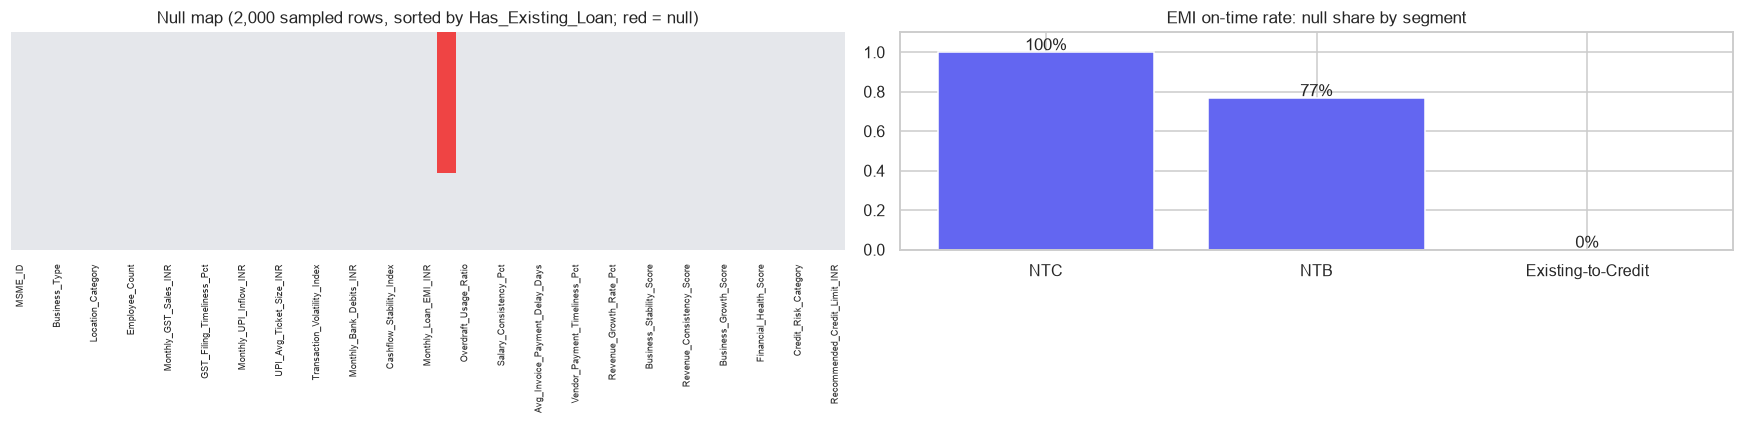

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
smp_rows = df.sample(2000, random_state=1).sort_values("Has_Existing_Loan")
sns.heatmap(smp_rows.isna(), cbar=False, ax=axes[0], cmap=["#E5E7EB", "#EF4444"], yticklabels=False)
axes[0].set_title("Null map (2,000 sampled rows, sorted by Has_Existing_Loan; red = null)")
axes[0].tick_params(axis="x", labelsize=6)
miss_seg = df.groupby("Customer_Segment").EMI_On_Time_Rate_Pct.apply(lambda s: s.isna().mean()).reindex(["NTC", "NTB", "Existing-to-Credit"])
axes[1].bar(miss_seg.index, miss_seg.values, color="#6366F1")
for i, v in enumerate(miss_seg.values):
    axes[1].text(i, v + 0.01, f"{v:.0%}", ha="center")
axes[1].set_title("EMI on-time rate: null share by segment")
axes[1].set_ylim(0, 1.1)
plt.tight_layout()
plt.show()

### 2c. Hidden nulls: zeros that mean "not applicable"

A null count of 0 does not mean a column is fully informative. Some zeros are really **"does not apply"**.

In [9]:
zeros = (df[NUMERIC_RAW] == 0).sum()
zeros = zeros[zeros > 0].to_frame("zero_count")
zeros["zero_%"] = (zeros.zero_count / len(df) * 100).round(2)
zeros["zero_when_no_loan_%"] = [round(((df[c] == 0) & (df.Has_Existing_Loan == "No")).sum() / max(z, 1) * 100, 1) for c, z in zeros.zero_count.items()]
zeros

,zero_count,zero_%,zero_when_no_loan_%
Monthly_Loan_EMI_INR,32556,65.11,100.0
Overdraft_Usage_Ratio,53,0.11,64.2
Avg_Invoice_Payment_Delay_Days,339,0.68,58.1
Revenue_Growth_Rate_Pct,112,0.22,65.2
Credit_History_Months,32556,65.11,100.0


**Takeaway:**
- `Monthly_Loan_EMI_INR` = 0 and `Credit_History_Months` = 0 for exactly the **32,556 businesses with no loan**, the same rows where EMI on-time rate is null. These three columns describe one fact, "no credit history", so the `Thin_File` flag captures it in a single feature.
- The few zeros in overdraft use, invoice delay and growth are genuine values (no overdraft, paid on the day, flat sales), not missing data.

### 2d. Floors and caps: values piled up at a boundary

Generated data often clips values at a minimum or maximum. A spike at the edge would distort averages and tell us the column is censored.

In [10]:
edge = pd.DataFrame({
    "min": df[NUMERIC_RAW].min(), "share_at_min_%": [(df[c] == df[c].min()).mean() * 100 for c in NUMERIC_RAW],
    "max": df[NUMERIC_RAW].max(), "share_at_max_%": [(df[c] == df[c].max()).mean() * 100 for c in NUMERIC_RAW],
}).round(2)
edge[(edge["share_at_min_%"] > 0.5) | (edge["share_at_max_%"] > 0.5)]

,min,share_at_min_%,max,share_at_max_%
Employee_Count,1.0,26.60,102.0,0.00
GST_Filing_Timeliness_Pct,50.2,0.00,100.0,1.47
Average_Bank_Balance_INR,5000.0,0.70,16658805.0,0.00
Monthly_Loan_EMI_INR,0.0,65.11,5786952.0,0.00
EMI_On_Time_Rate_Pct,69.4,0.00,100.0,0.62
Salary_Consistency_Pct,53.4,0.00,100.0,0.81
Employee_Attrition_Rate_Pct,1.0,2.51,44.9,0.00
Avg_Invoice_Payment_Delay_Days,0.0,0.68,96.8,0.00
Vendor_Payment_Timeliness_Pct,49.6,0.00,100.0,1.11
Credit_History_Months,0.0,65.11,180.0,0.05


**Takeaway:**
- **Employee count = 1 for 27%** of businesses. That is real: sole proprietors with no staff. It is the largest boundary pile-up and is not an error.
- Percentage columns have **1–1.5% at exactly 100%** (GST filing, vendor payments, salary, EMI). These are **capped** values: "100% on time" means "at least as good as we can measure". Tree models handle this naturally.
- Small floors: bank balance at ₹5,000 (0.7%), attrition at 1% (2.5%). Too small to matter.
- EMI = 0 and credit history = 0 for 65% are the "no loan" rows from 2c, not a cap.

### 2e. Summary statistics

In [11]:
desc = df[NUMERIC_RAW].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[NUMERIC_RAW].skew()
desc["cv"] = desc["std"] / desc["mean"]   # coefficient of variation: spread relative to the average
desc.round(3)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,cv
Years_in_Operation,50000.0,5.059,3.399000e+00,0.200,0.400,2.600,4.300,6.800,1.610000e+01,2.940000e+01,1.305,0.672
Employee_Count,50000.0,3.847,4.058000e+00,1.000,1.000,1.000,3.000,5.000,2.000000e+01,1.020000e+02,4.198,1.055
Annual_Turnover_INR,50000.0,8480063.602,1.163387e+07,300000.000,448888.450,2462124.500,4928700.000,9978110.500,5.429333e+07,2.548860e+08,5.594,1.372
Monthly_GST_Sales_INR,50000.0,692504.184,9.543729e+05,19833.000,36302.790,199705.250,401682.000,812523.000,4.460091e+06,2.304039e+07,5.632,1.378
Monthly_GST_Purchases_INR,50000.0,436397.628,6.203794e+05,7191.000,21139.950,120996.000,249107.500,508181.250,2.908300e+06,1.547203e+07,5.816,1.422
GST_Filing_Timeliness_Pct,50000.0,84.035,7.577000e+00,50.200,65.300,79.100,84.400,89.300,1.000000e+02,1.000000e+02,-0.246,0.090
Monthly_UPI_Inflow_INR,50000.0,243405.709,3.799204e+05,1286.000,8323.920,59143.750,129439.500,279712.000,1.718944e+06,1.351099e+07,7.756,1.561
Monthly_UPI_Outflow_INR,50000.0,141079.530,2.281698e+05,375.000,4191.900,32272.750,72570.500,159771.250,1.049579e+06,8.168324e+06,7.449,1.617
UPI_Avg_Ticket_Size_INR,50000.0,956.498,1.521181e+03,100.000,123.000,302.000,491.000,996.000,7.114060e+03,6.098000e+04,8.176,1.590
UPI_Daily_Txn_Count,50000.0,10.412,6.252000e+00,0.100,0.900,6.000,9.400,13.600,3.000000e+01,8.210000e+01,1.188,0.600


### 2f. Outliers (IQR rule)

A value is flagged if it lies more than 1.5 × IQR below the 25th or above the 75th percentile. For skewed money columns we check on the **log scale**, which is how a model sees them.

In [12]:
def iqr_share(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

money_cols = [c for c in NUMERIC_RAW if c.endswith("_INR")]
out = pd.DataFrame({
    "outlier_%_raw": [iqr_share(df[c].dropna()) for c in NUMERIC_RAW],
    "outlier_%_log": [iqr_share(np.log1p(df[c].dropna())) if c in money_cols else np.nan for c in NUMERIC_RAW],
}, index=NUMERIC_RAW).round(2)
out.sort_values("outlier_%_raw", ascending=False).head(15)

,outlier_%_raw,outlier_%_log
Monthly_Loan_EMI_INR,15.10,0.00
Credit_History_Months,10.70,NaN
UPI_Avg_Ticket_Size_INR,10.35,1.47
Monthly_UPI_Outflow_INR,8.79,0.75
Average_Bank_Balance_INR,8.70,1.30
Monthly_UPI_Inflow_INR,8.67,0.70
Monthly_GST_Purchases_INR,8.27,0.55
Monthly_Bank_Credits_INR,8.24,0.51
Monthly_GST_Sales_INR,8.16,0.51
Monthly_Bank_Debits_INR,8.13,0.51


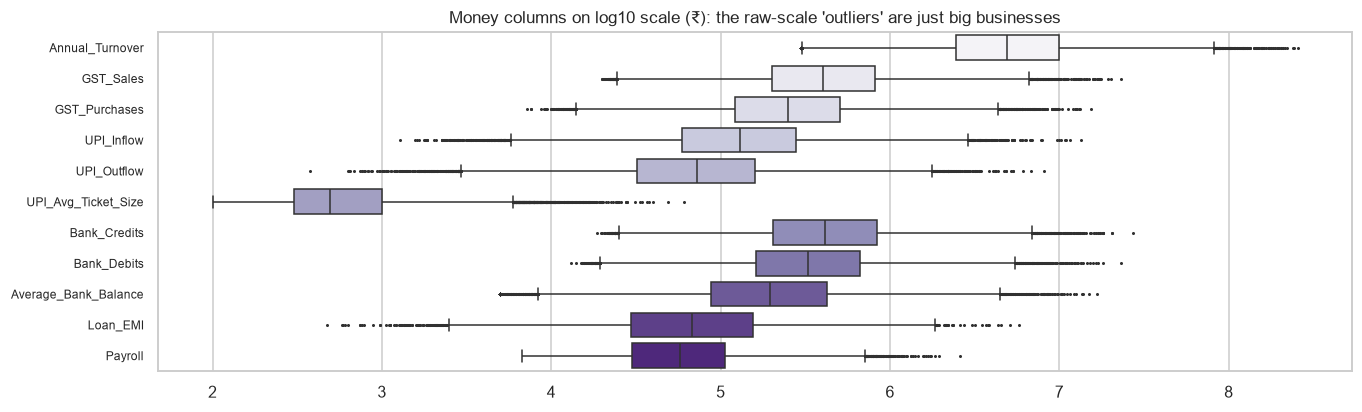

In [13]:
fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=np.log10(df[money_cols].replace(0, np.nan)), orient="h", ax=ax, palette="Purples", fliersize=1)
ax.set_yticklabels([c.replace("_INR", "").replace("Monthly_", "") for c in money_cols], fontsize=8)
ax.set_title("Money columns on log10 scale (₹): the raw-scale 'outliers' are just big businesses")
plt.show()

**Takeaway:** about 8% of businesses look like outliers on the raw rupee scale, but almost none do on the log scale. They are **large businesses, not errors**, so we keep them. `Monthly_Loan_EMI_INR` and `Credit_History_Months` look like outliers only because 65% of values are zero (no loan). We do not clip or drop rows; real anomalies are caught by the cross-source rules and the Isolation Forest instead.

### 2g. Categorical columns: levels and balance

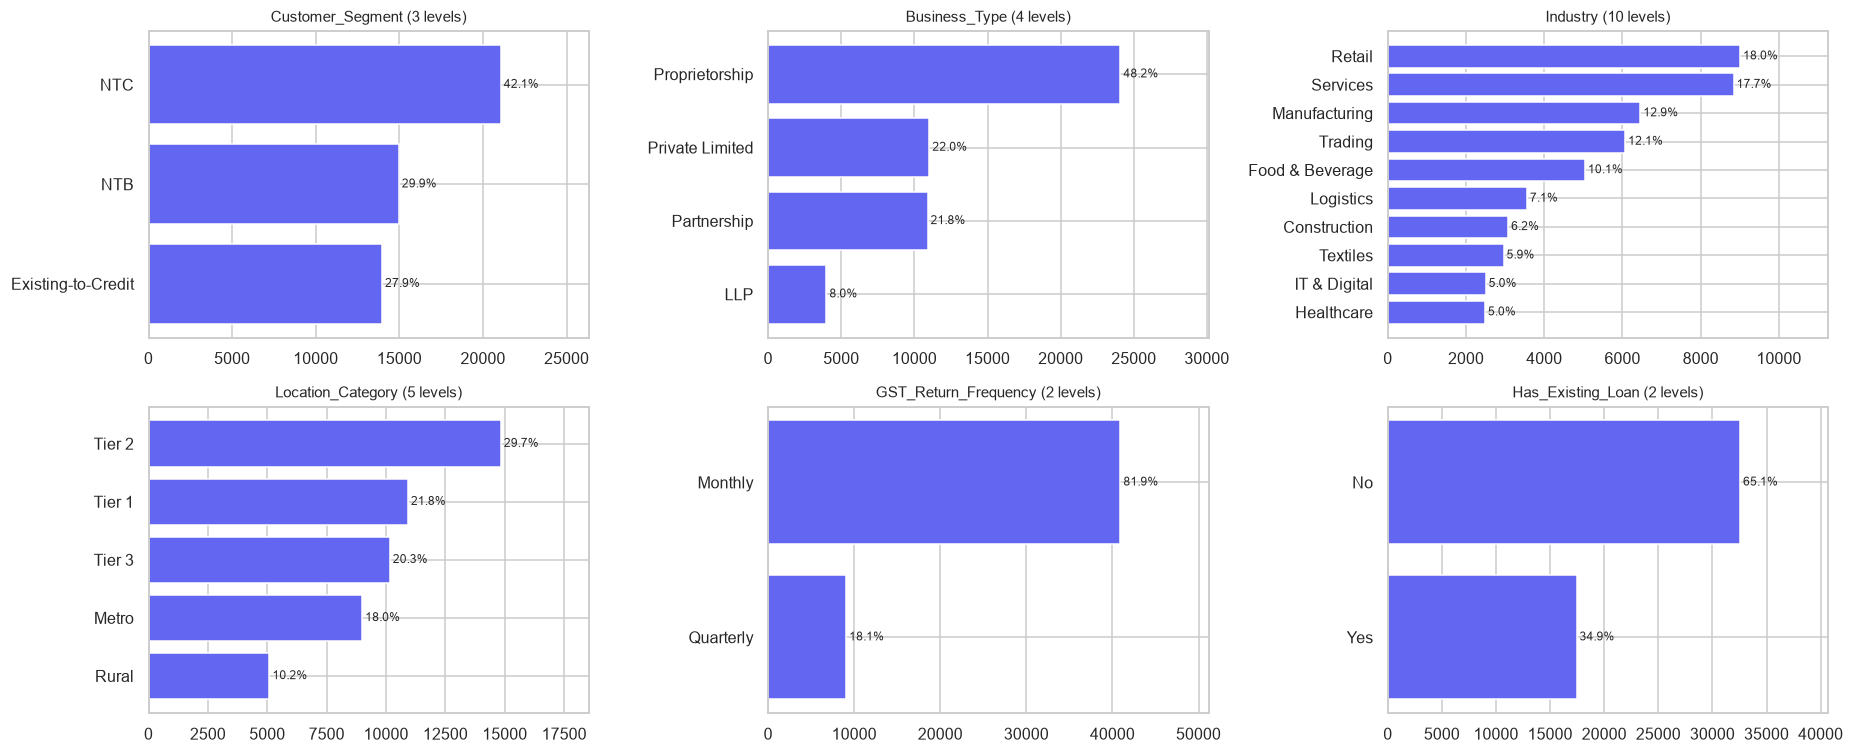

Smallest level of any category: (np.int64(2485), 'Industry')


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for ax, col in zip(axes.flat, CATEGORICAL):
    vc = df[col].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color="#6366F1")
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v, i, f" {v / len(df):.1%}", va="center", fontsize=8)
    ax.set_title(f"{col} ({len(vc)} levels)", fontsize=10)
    ax.set_xlim(0, vc.max() * 1.25)
plt.tight_layout()
plt.show()
print("Smallest level of any category:", min((df[c].value_counts().min(), c) for c in CATEGORICAL))

**Takeaway:** no rare levels (smallest is still ~2,500 rows), no typos or mixed spellings, low cardinality (≤10 levels). We can use the categories directly in LightGBM with no grouping of rare levels.

### 2h. How the categories relate to each other (Cramér's V)

Cramér's V is a 0–1 measure of association between two categorical columns (0 = unrelated, 1 = one fully decides the other).

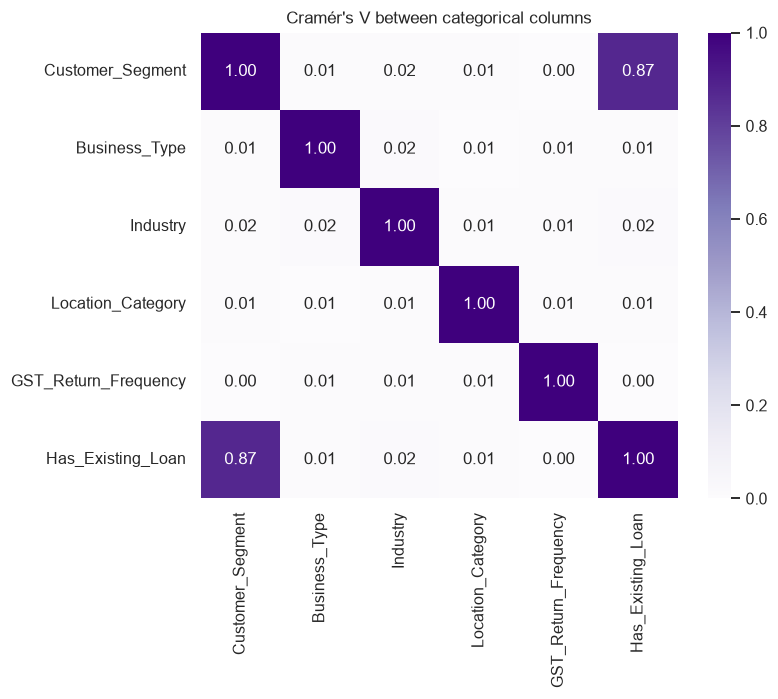

In [15]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

cv = pd.DataFrame([[cramers_v(df[a], df[b]) for b in CATEGORICAL] for a in CATEGORICAL], index=CATEGORICAL, columns=CATEGORICAL)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1)
plt.title("Cramér's V between categorical columns")
plt.show()

**Takeaway:** `Customer_Segment` and `Has_Existing_Loan` are strongly linked (NTC never has a loan). Everything else is close to independent, so industry, location and business type each add their own information.

### 2i. Multicollinearity among numeric inputs (VIF)

The variance inflation factor (VIF) asks: how well can the other columns predict this one? VIF above 10 means the column is mostly a copy of others. That matters for the linear baseline and for reading coefficients, not for tree models.

In [16]:
from sklearn.linear_model import LinearRegression as _LR
Xv = df[NUMERIC_RAW].drop(columns=["EMI_On_Time_Rate_Pct"]).copy()
Xv[money_cols] = np.log1p(Xv[money_cols])
vif = pd.Series({c: 1 / max(1 - _LR().fit(Xv.drop(columns=c), Xv[c]).score(Xv.drop(columns=c), Xv[c]), 1e-9) for c in Xv.columns})
vif.sort_values(ascending=False).round(1).to_frame("VIF").head(12)

,VIF
Monthly_Bank_Credits_INR,514.7
Monthly_GST_Sales_INR,417.7
Monthly_Bank_Debits_INR,204.2
Annual_Turnover_INR,161.0
Monthly_UPI_Inflow_INR,30.9
Monthly_GST_Purchases_INR,23.2
Monthly_UPI_Outflow_INR,17.4
Average_Bank_Balance_INR,12.1
UPI_Avg_Ticket_Size_INR,10.4
UPI_Daily_Txn_Count,5.0


**Takeaway:** the size columns have very high VIF: bank credits 515, GST sales 418, bank debits 204, turnover 161. They are near-copies of each other, as section 6 shows. The behavioural columns (GST timeliness, payroll and the rest) have VIF under 5, so each is a mostly independent signal. This is the main reason we build **ratios** (size-free) rather than feeding many raw rupee amounts.

## 3. The answer columns

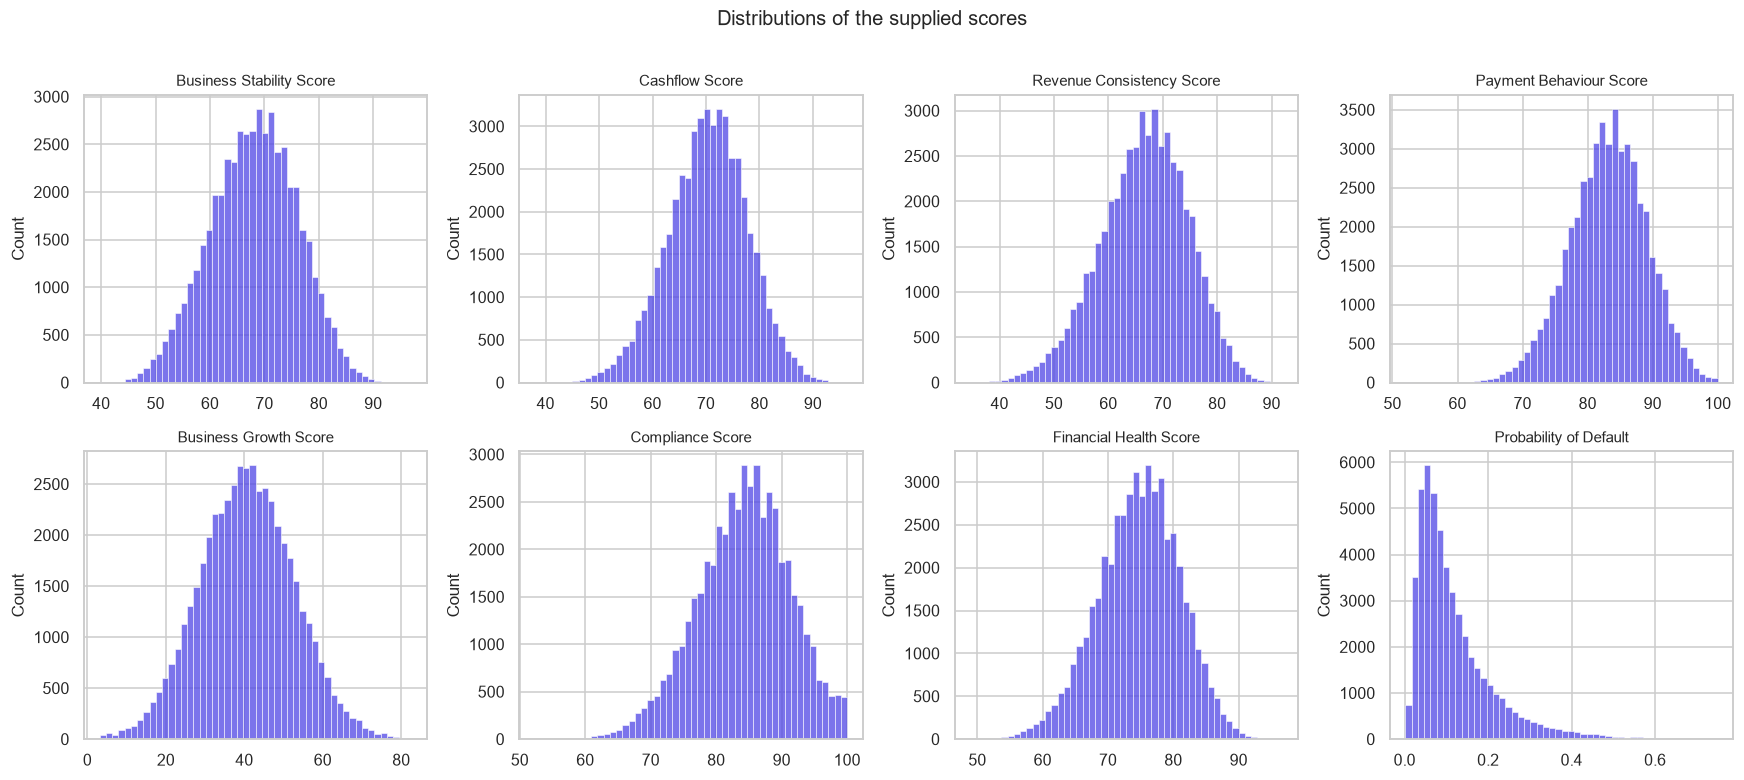

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, list(PILLARS) + ["Financial_Health_Score", "Probability_of_Default"]):
    sns.histplot(df[col], bins=50, ax=ax, color="#4F46E5", edgecolor=None)
    ax.set_title(col.replace("_", " "), fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Distributions of the supplied scores", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

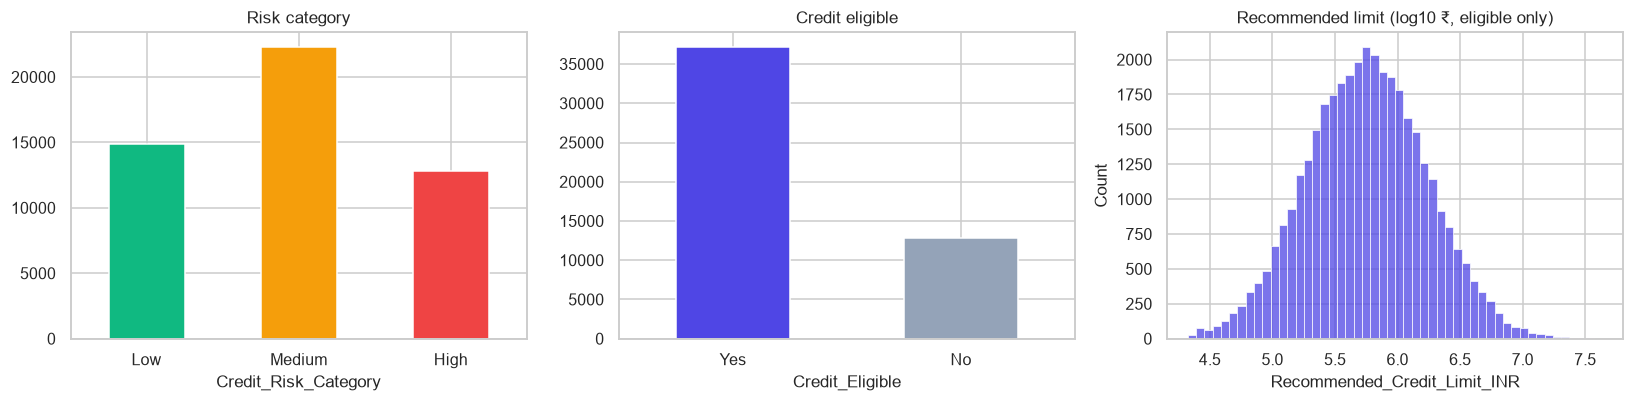

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
order = ["Low", "Medium", "High"]
df.Credit_Risk_Category.value_counts().reindex(order).plot.bar(ax=axes[0], color=["#10B981", "#F59E0B", "#EF4444"])
axes[0].set_title("Risk category")
df.Credit_Eligible.value_counts().plot.bar(ax=axes[1], color=["#4F46E5", "#94A3B8"])
axes[1].set_title("Credit eligible")
sns.histplot(np.log10(df.loc[df.Recommended_Credit_Limit_INR > 0, "Recommended_Credit_Limit_INR"]), bins=50, ax=axes[2], color="#4F46E5")
axes[2].set_title("Recommended limit (log10 ₹, eligible only)")
for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Observations**
- The Business Growth pillar sits much lower (mean ≈ 41) than the others (66–84). Pillars have **different natural ranges**, so a fixed "A ≥ 80" grade would be unfair to Growth. We grade pillars by **percentile** instead.
- The PD is right-skewed (median 9%, max 75%), so we model it on the **log-odds** scale.

## 4. Reverse-engineering how the answers were built

A key question for an interview: *is the target learnable, and what is it really?*

### 4a. Overall score vs the six pillars

R² of a linear blend of pillars: 0.831


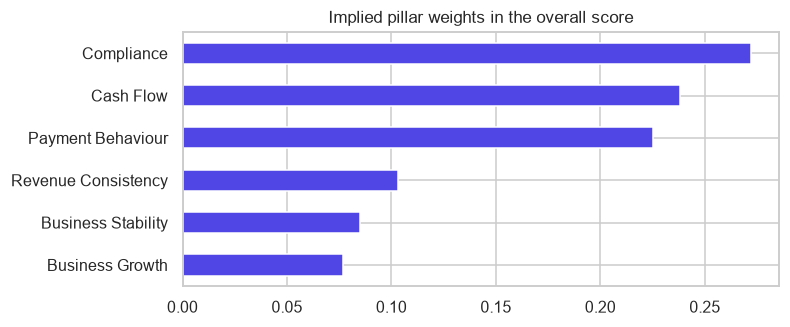

In [19]:
lr = LinearRegression().fit(df[list(PILLARS)], df.Financial_Health_Score)
w = pd.Series(lr.coef_, index=[PILLARS[c] for c in PILLARS]).sort_values(ascending=False)
print(f"R² of a linear blend of pillars: {lr.score(df[list(PILLARS)], df.Financial_Health_Score):.3f}")
ax = (w / w.sum()).plot.barh(color="#4F46E5", figsize=(7, 3))
ax.set_title("Implied pillar weights in the overall score")
ax.invert_yaxis()
plt.show()

The overall score is ≈ **28% Compliance + 24% Cash Flow + 23% Payment Behaviour + 11% Revenue Consistency + 9% Stability + 8% Growth**, plus noise (R² 0.83, so 17% is not explained by the pillars).

### 4b. PD vs overall score

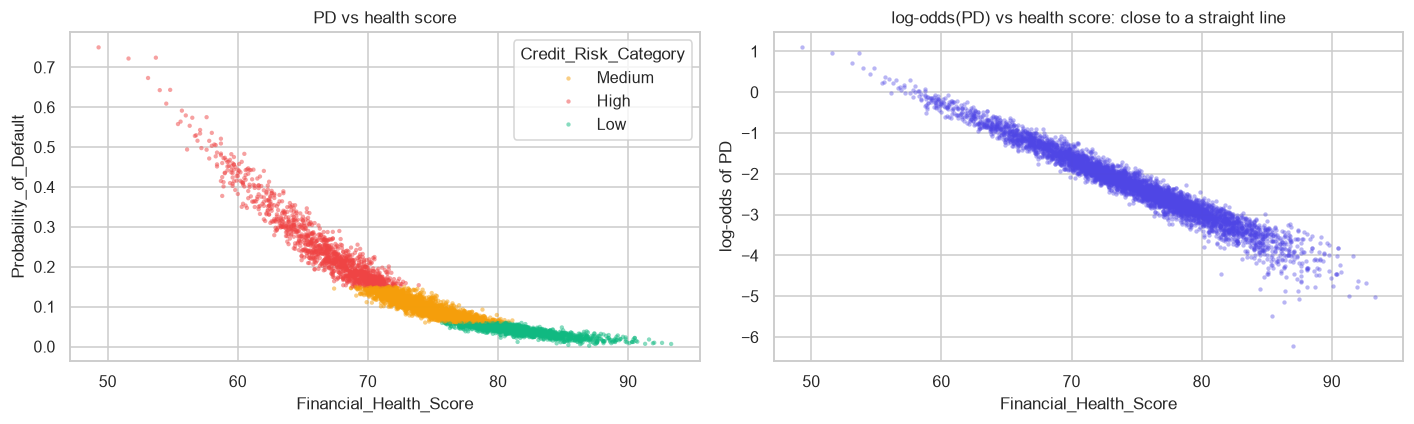

R² of log-odds(PD) on the score alone: 0.955


In [20]:
logit_pd = np.log(df.Probability_of_Default / (1 - df.Probability_of_Default))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
smp = df.sample(5000, random_state=0)
sns.scatterplot(x=smp.Financial_Health_Score, y=smp.Probability_of_Default, hue=smp.Credit_Risk_Category,
                palette={"Low": "#10B981", "Medium": "#F59E0B", "High": "#EF4444"}, s=8, alpha=0.5, ax=axes[0], linewidth=0)
axes[0].set_title("PD vs health score")
sns.scatterplot(x=smp.Financial_Health_Score, y=logit_pd[smp.index], s=8, alpha=0.4, ax=axes[1], color="#4F46E5", linewidth=0)
axes[1].set_title("log-odds(PD) vs health score: close to a straight line")
axes[1].set_ylabel("log-odds of PD")
plt.tight_layout()
plt.show()
r2 = LinearRegression().fit(df[["Financial_Health_Score"]], logit_pd).score(df[["Financial_Health_Score"]], logit_pd)
print(f"R² of log-odds(PD) on the score alone: {r2:.3f}")

### 4c. Risk category, eligibility and limit rules

In [21]:
rules = df.groupby("Credit_Risk_Category").agg(PD_min=("Probability_of_Default", "min"), PD_max=("Probability_of_Default", "max"),
                                                eligible=("Credit_Eligible", lambda s: (s == "Yes").mean()))
el = df[df.Recommended_Credit_Limit_INR > 0]
rules["limit_÷_turnover_median"] = (el.Recommended_Credit_Limit_INR / el.Annual_Turnover_INR).groupby(el.Credit_Risk_Category).median()
rules.reindex(order).style.format({"eligible": "{:.1%}", "limit_÷_turnover_median": "{:.1%}"})

,PD_min,PD_max,eligible,limit_÷_turnover_median
Credit_Risk_Category,,,,
Low,0.002000,0.060000,100.0%,16.2%
Medium,0.060000,0.150000,100.0%,8.4%
High,0.150000,0.750000,0.0%,nan%


**Takeaway: the decision layer is a clear policy.**
- Risk band = PD < 6% → Low, 6–15% → Medium, > 15% → High.
- Eligible = not High.
- Limit ≈ 16% of turnover (Low) or 8% (Medium), rounded to ₹1,000.

So the ML problem is **predicting PD (and the scores)** from behaviour. The decision is a transparent policy on top. That is how real lenders separate the *model* from the *credit policy*.

There are **no observed defaults** in the data. PD is itself a generated number. We will be explicit about this in the model report.

## 5. Numeric inputs: distributions

In [22]:
money = [c for c in NUMERIC_RAW if c.endswith("_INR")]
other = [c for c in NUMERIC_RAW if c not in money]
print("Skewness of money columns (raw → log):")
print(pd.DataFrame({"raw": df[money].skew(), "log1p": np.log1p(df[money]).skew()}).round(2).to_string())

Skewness of money columns (raw → log):
                            raw  log1p
Annual_Turnover_INR        5.59   0.03
Monthly_GST_Sales_INR      5.63   0.03
Monthly_GST_Purchases_INR  5.82   0.03
Monthly_UPI_Inflow_INR     7.76  -0.08
Monthly_UPI_Outflow_INR    7.45  -0.09
UPI_Avg_Ticket_Size_INR    8.18   0.77
Monthly_Bank_Credits_INR   5.73   0.03
Monthly_Bank_Debits_INR    5.92   0.03
Average_Bank_Balance_INR   6.77  -0.19
Monthly_Loan_EMI_INR       9.59   0.69
Monthly_Payroll_INR        4.42   0.36


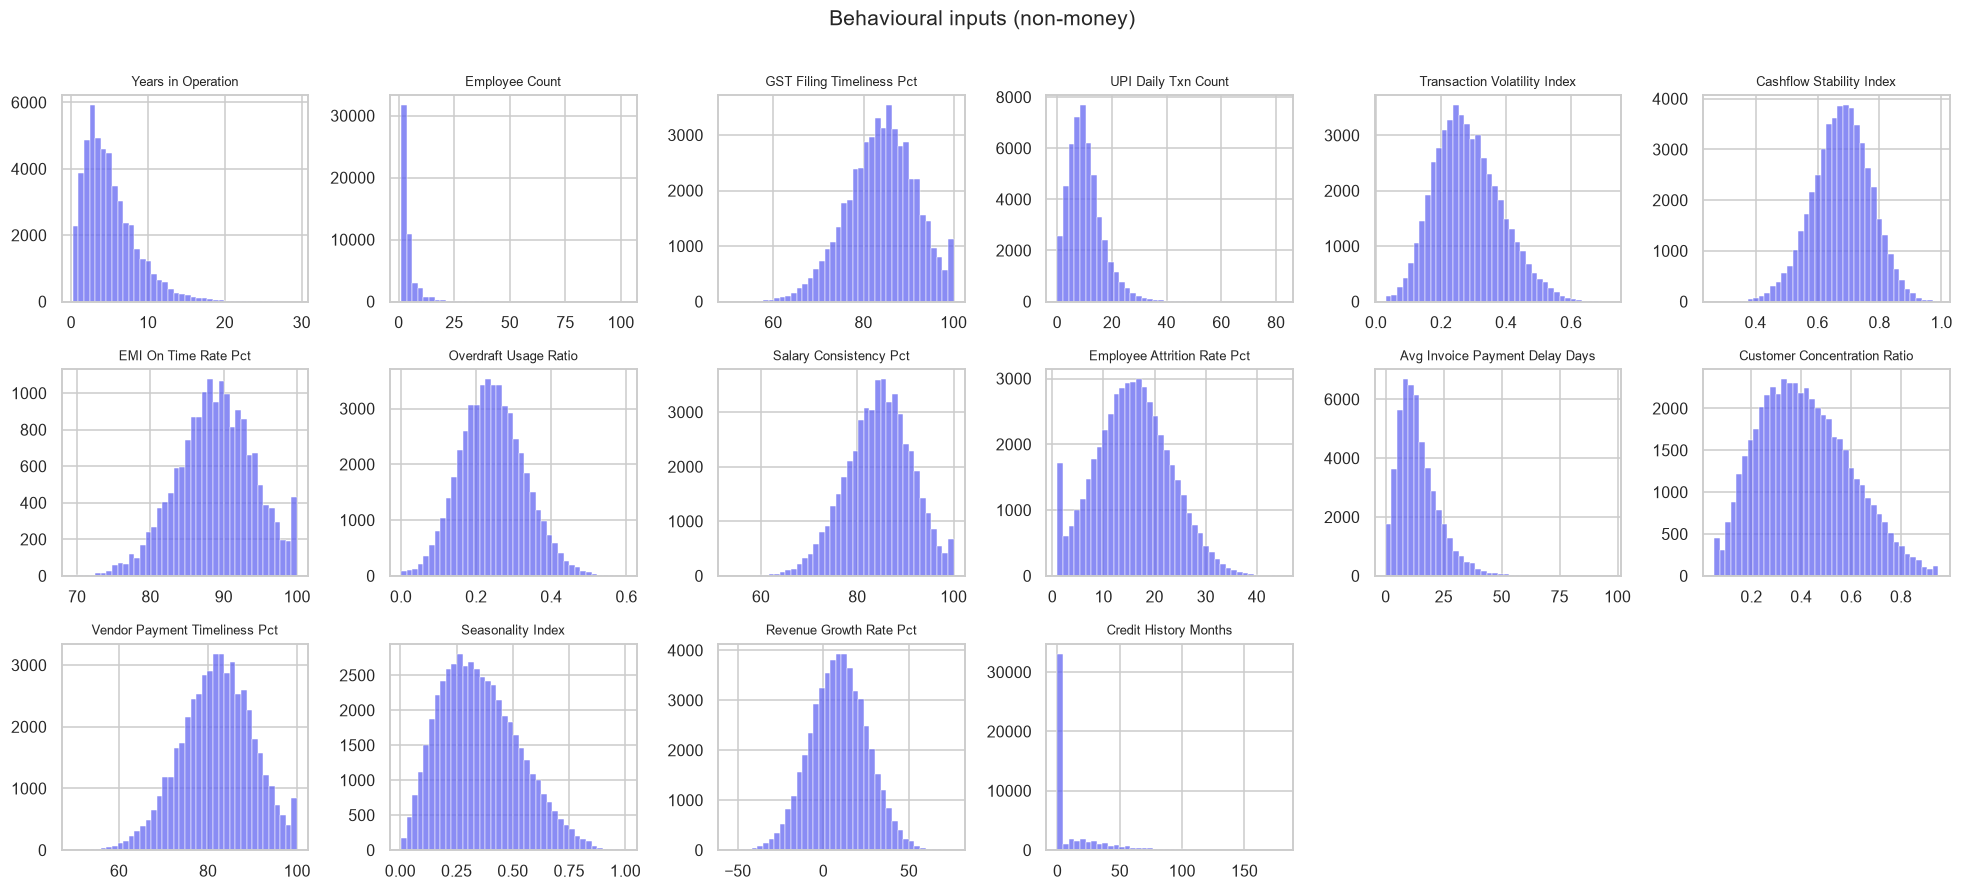

In [23]:
fig, axes = plt.subplots(3, 6, figsize=(18, 8))
for ax, col in zip(axes.flat, other):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color="#6366F1", edgecolor=None)
    ax.set_title(col.replace("_", " "), fontsize=8.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(other):]:
    ax.axis("off")
plt.suptitle("Behavioural inputs (non-money)", y=1.01)
plt.tight_layout()
plt.show()

**Takeaway:** money columns are heavily right-skewed (skew 4–10, close to 0 after a log). They span ₹20 K to ₹2 Cr+ per month. Tree models don't mind; for the linear baseline and for comparing businesses, **ratios** (surplus ÷ credits, EMI ÷ credits…) are far more meaningful than raw rupees. Behavioural percentages are roughly bell-shaped and well-behaved.

## 6. Money columns are near-duplicates of each other

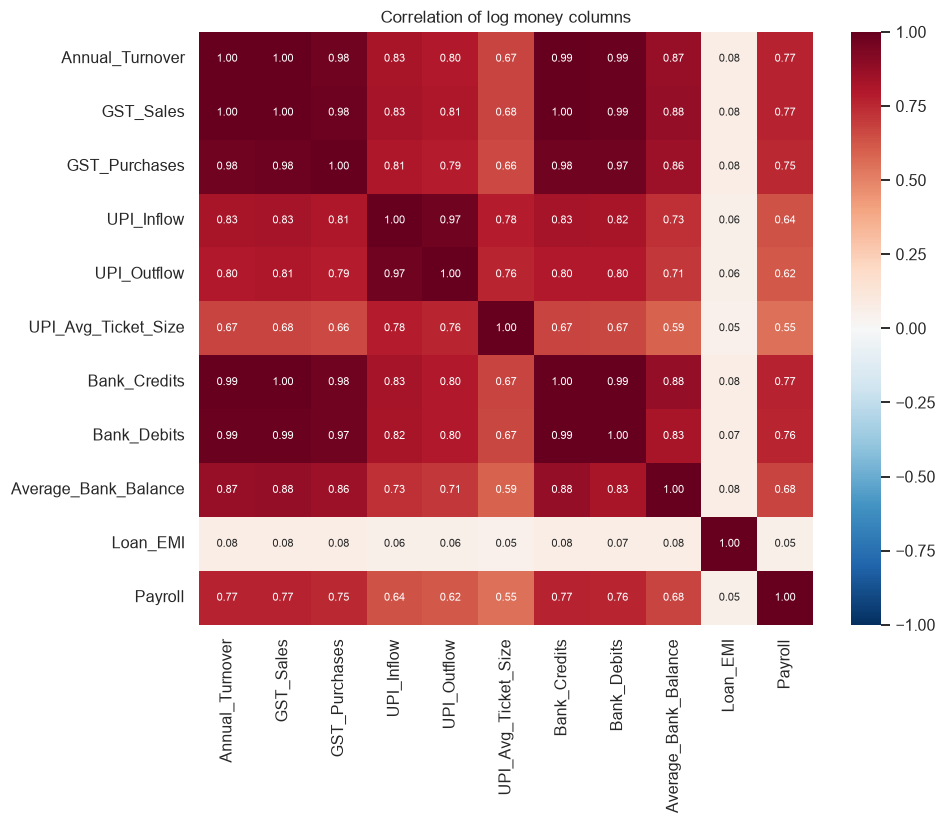

In [24]:
corr_money = np.log1p(df[money]).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_money, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            xticklabels=[c.replace("_INR", "").replace("Monthly_", "") for c in money],
            yticklabels=[c.replace("_INR", "").replace("Monthly_", "") for c in money], annot_kws={"size": 7})
plt.title("Correlation of log money columns")
plt.show()

In [25]:
ratio = df.UPI_Avg_Ticket_Size_INR * df.UPI_Daily_Txn_Count * 30 / df.Monthly_UPI_Inflow_INR
print(f"UPI inflow ÷ (ticket × daily txns × 30): median {1 / ratio.median():.3f} → 30 × {1/ratio.median():.3f} = {30 / ratio.median():.1f} working days")

UPI inflow ÷ (ticket × daily txns × 30): median 0.867 → 30 × 0.867 = 26.0 working days


**Takeaway:** turnover, GST sales, bank credits and debits are 0.95+ correlated: they all measure **size**. Size says how *much* to lend, not how *risky* the business is. So we build **size-free ratios**. Also, UPI inflow = ticket × daily transactions × 26 working days, so those three columns carry one piece of information.

## 7. What relates to default risk?

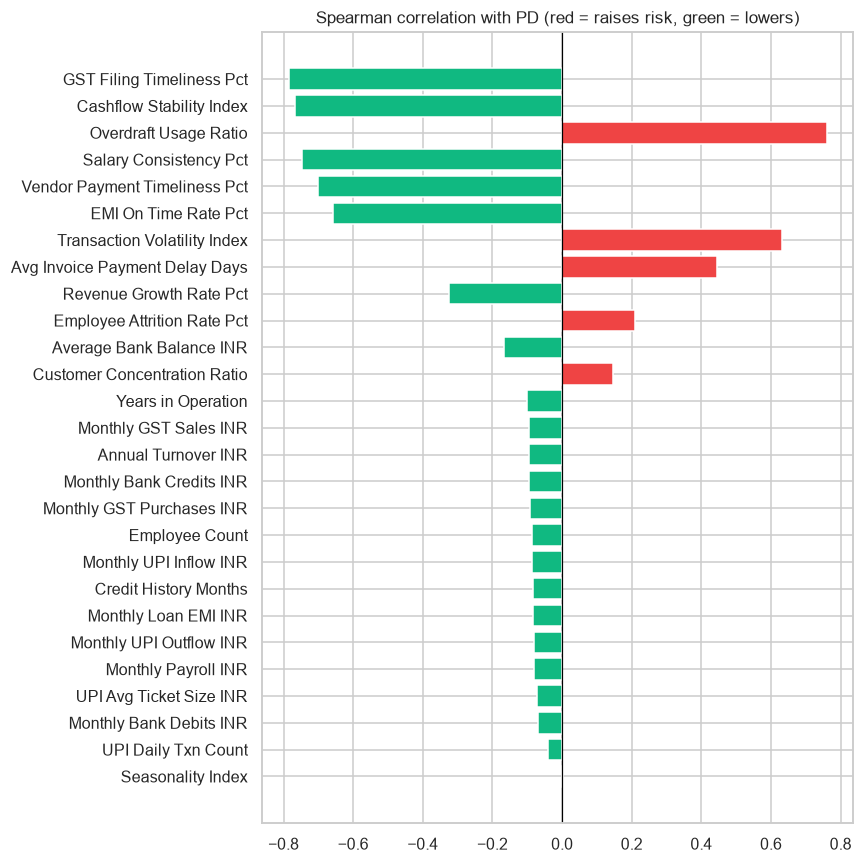

In [26]:
corr_pd = df[NUMERIC_RAW + ["Probability_of_Default"]].corr(method="spearman")["Probability_of_Default"].drop("Probability_of_Default")
corr_pd = corr_pd.reindex(corr_pd.abs().sort_values(ascending=True).index)
plt.figure(figsize=(8, 8))
plt.barh([c.replace("_", " ") for c in corr_pd.index], corr_pd.values,
         color=["#EF4444" if v > 0 else "#10B981" for v in corr_pd.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Spearman correlation with PD (red = raises risk, green = lowers)")
plt.tight_layout()
plt.show()

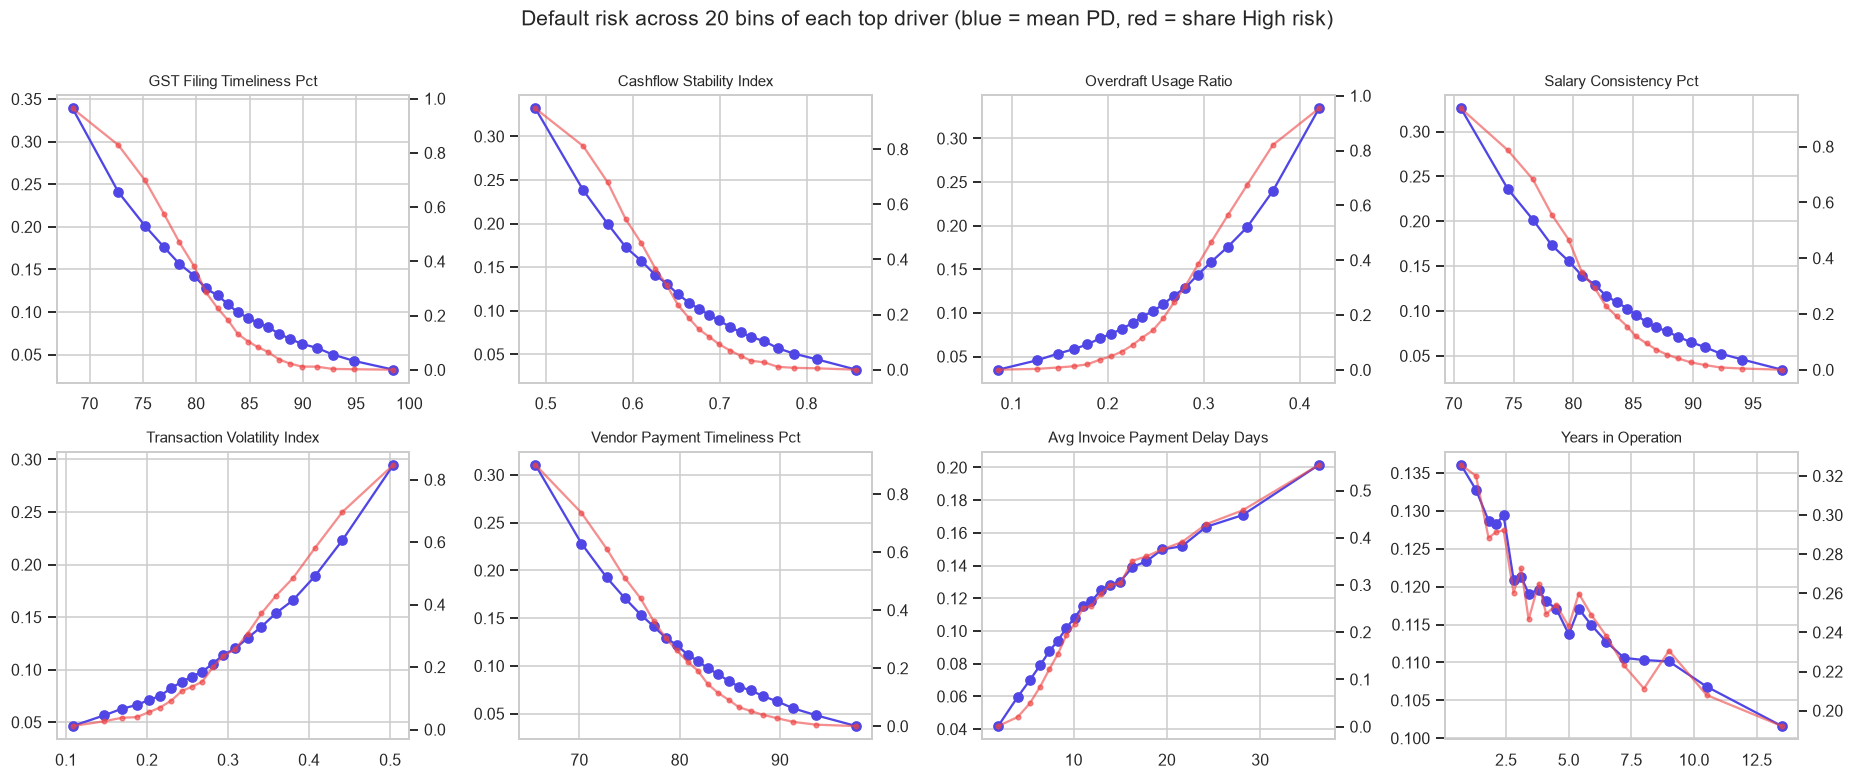

In [27]:
top = ["GST_Filing_Timeliness_Pct", "Cashflow_Stability_Index", "Overdraft_Usage_Ratio", "Salary_Consistency_Pct",
       "Transaction_Volatility_Index", "Vendor_Payment_Timeliness_Pct", "Avg_Invoice_Payment_Delay_Days", "Years_in_Operation"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.flat, top):
    b = pd.qcut(df[col], 20, duplicates="drop")
    g = df.groupby(b, observed=True).agg(x=(col, "median"), pd_=("Probability_of_Default", "mean"), high=("Credit_Risk_Category", lambda s: (s == "High").mean()))
    ax.plot(g.x, g.pd_, marker="o", color="#4F46E5", label="mean PD")
    ax2 = ax.twinx()
    ax2.plot(g.x, g.high, marker=".", color="#EF4444", alpha=0.6, label="% High risk")
    ax2.grid(False)
    ax.set_title(col.replace("_", " "), fontsize=10)
plt.suptitle("Default risk across 20 bins of each top driver (blue = mean PD, red = share High risk)", y=1.01)
plt.tight_layout()
plt.show()

**Takeaway:**
- The strongest risk signals are **behavioural discipline**: GST filed on time, cash-flow stability, overdraft use, salary consistency, transaction volatility. Size barely matters.
- Every relationship is **smooth and monotonic** (no U-shapes). That justifies **monotonic constraints** in the model, and it is also why a linear model already performs well.

## 8. Are NTC businesses riskier?

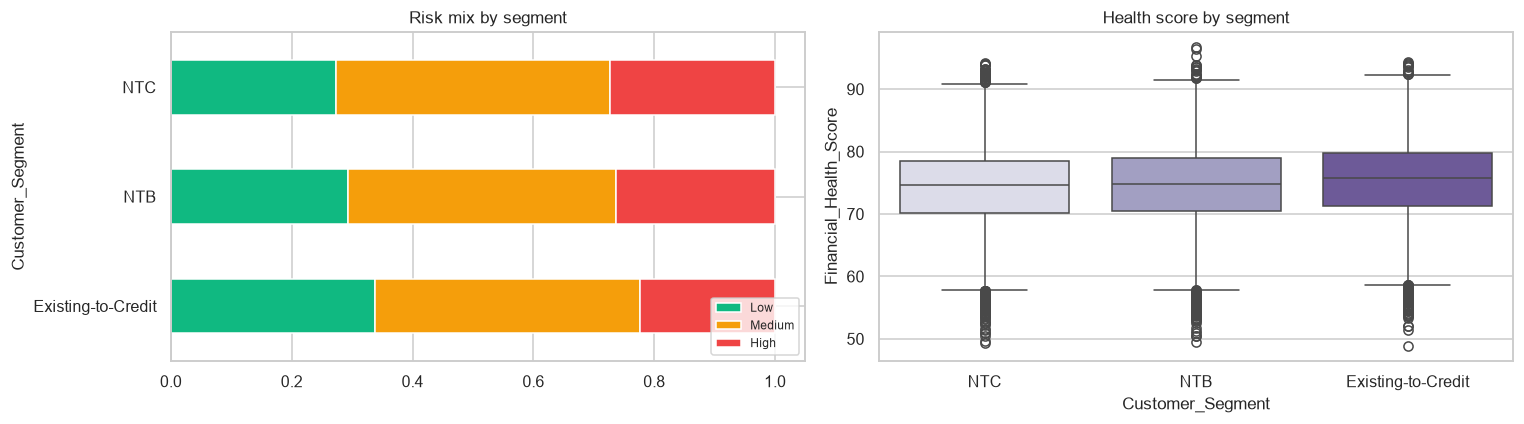

,Financial_Health_Score,Probability_of_Default
Customer_Segment,,
Existing-to-Credit,75.398,0.110
NTB,74.524,0.121
NTC,74.287,0.123


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
mix = pd.crosstab(df.Customer_Segment, df.Credit_Risk_Category, normalize="index")[order]
mix.plot.barh(stacked=True, color=["#10B981", "#F59E0B", "#EF4444"], ax=axes[0])
axes[0].set_title("Risk mix by segment")
axes[0].legend(loc="lower right", fontsize=8)
sns.boxplot(data=df, x="Customer_Segment", y="Financial_Health_Score", ax=axes[1], palette="Purples", order=["NTC", "NTB", "Existing-to-Credit"])
axes[1].set_title("Health score by segment")
plt.tight_layout()
plt.show()
df.groupby("Customer_Segment")[["Financial_Health_Score", "Probability_of_Default"]].mean().round(3)

**Takeaway (core business case):** NTC businesses are only slightly riskier (27% High vs 22% for existing borrowers). **About 73% of NTC businesses are not High risk**, yet a bureau-only lender would reject all of them for lack of history. That is the financial-inclusion opportunity the assignment talks about, and it is quantified here.

## 9. Industry, location and business type

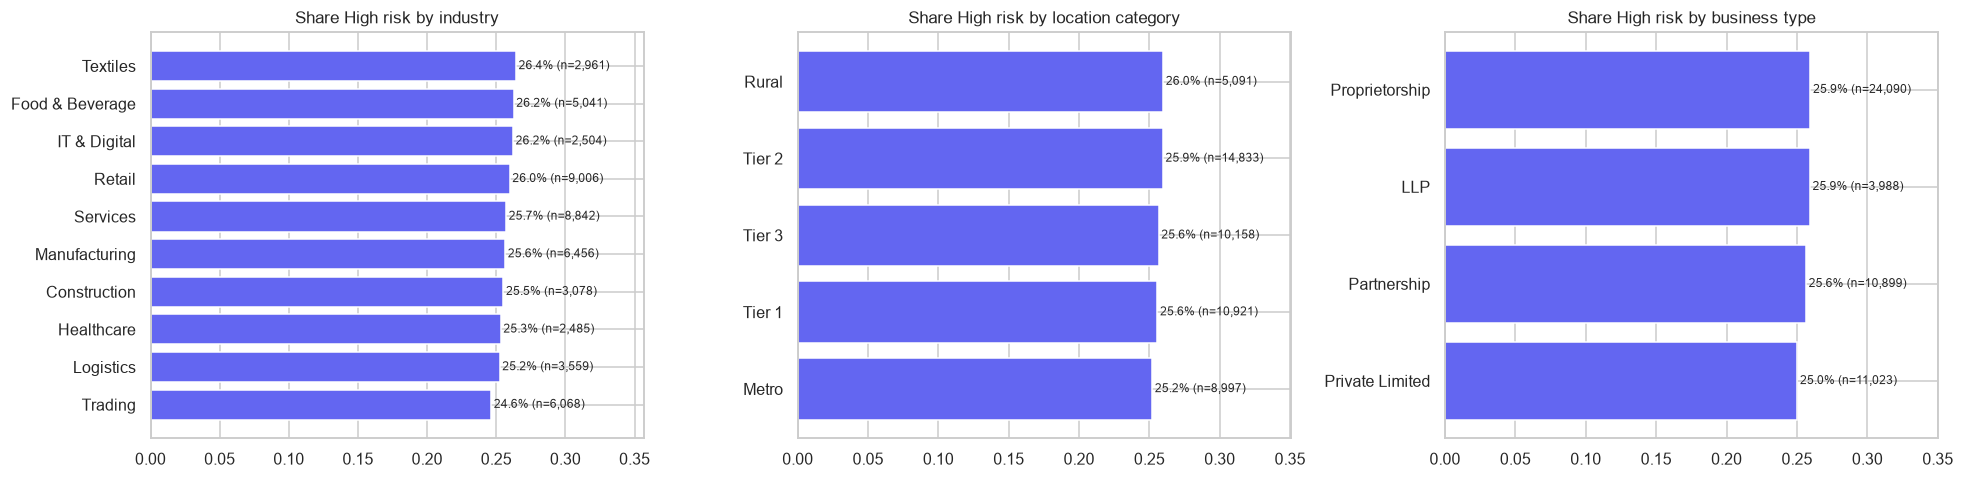

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["Industry", "Location_Category", "Business_Type"]):
    g = df.groupby(col).agg(high=("Credit_Risk_Category", lambda s: (s == "High").mean()), n=("MSME_ID", "size")).sort_values("high")
    ax.barh(g.index, g.high, color="#6366F1")
    for i, (h, n) in enumerate(zip(g.high, g.n)):
        ax.text(h + 0.002, i, f"{h:.1%} (n={n:,})", va="center", fontsize=8)
    ax.set_title(f"Share High risk by {col.replace('_', ' ').lower()}")
    ax.set_xlim(0, g.high.max() * 1.35)
plt.tight_layout()
plt.show()

**Takeaway:** risk differs only a little between industries and locations. This justifies **peer benchmarking within industry × location** (a fair comparison) rather than treating the category itself as a big risk driver.

## 10. Seasonality

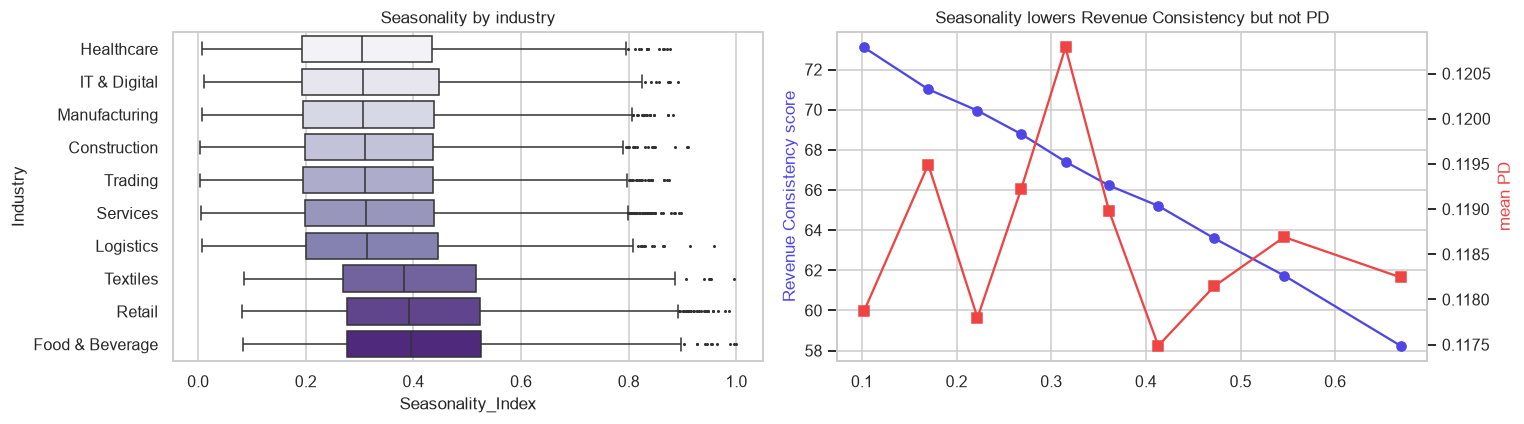

Correlation of seasonality with volatility and cash-flow stability:
Seasonality_Index               1.0
Transaction_Volatility_Index    0.0
Cashflow_Stability_Index       -0.0


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order_ind = df.groupby("Industry").Seasonality_Index.median().sort_values().index
sns.boxplot(data=df, y="Industry", x="Seasonality_Index", order=order_ind, ax=axes[0], palette="Purples", fliersize=1)
axes[0].set_title("Seasonality by industry")
b = pd.qcut(df.Seasonality_Index, 10)
g = df.groupby(b, observed=True).agg(x=("Seasonality_Index", "median"), rc=("Revenue_Consistency_Score", "mean"), pd_=("Probability_of_Default", "mean"))
axes[1].plot(g.x, g.rc, marker="o", color="#4F46E5")
axes[1].set_ylabel("Revenue Consistency score", color="#4F46E5")
ax2 = axes[1].twinx()
ax2.plot(g.x, g.pd_, marker="s", color="#EF4444")
ax2.set_ylabel("mean PD", color="#EF4444")
ax2.grid(False)
axes[1].set_title("Seasonality lowers Revenue Consistency but not PD")
plt.tight_layout()
plt.show()
print("Correlation of seasonality with volatility and cash-flow stability:")
print(df[["Seasonality_Index", "Transaction_Volatility_Index", "Cashflow_Stability_Index"]].corr().round(2).iloc[0].to_string())

**Takeaway:**
- Seasonality is mostly an **industry trait** and is independent of volatility (corr 0.00). It's a separate dimension: predictable swings are not the same as erratic ones.
- It lowers the Revenue Consistency pillar (Spearman −0.53) but has no measurable link to the supplied PD (0.003).
- For a lender, though, seasonality matters for **cash planning**: can the EMI be paid in the lean month? That motivates our **lean-month stress test** feature and the seasonal EMI condition in the credit decision.

## 11. Do the data sources agree?

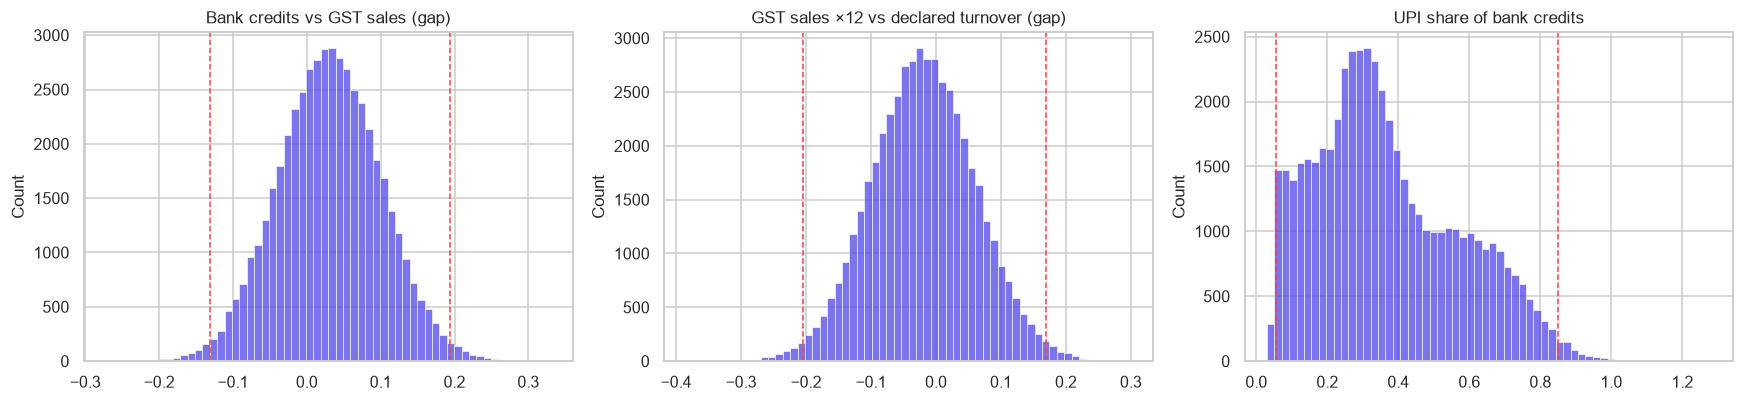

1st / 99th percentiles → gap GST-bank: [-0.131, 0.194] | GST-turnover: [-0.205, 0.169]


Location_Category
Metro     0.330
Tier 1    0.332
Tier 2    0.332
Rural     0.334
Tier 3    0.334
Name: upi_share, dtype: float64

In [31]:
gst_bank = (df.Monthly_Bank_Credits_INR - df.Monthly_GST_Sales_INR) / df.Monthly_GST_Sales_INR
gst_turn = df.Monthly_GST_Sales_INR * 12 / df.Annual_Turnover_INR - 1
upi_share = df.Monthly_UPI_Inflow_INR / df.Monthly_Bank_Credits_INR
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, s, t in zip(axes, [gst_bank, gst_turn, upi_share], ["Bank credits vs GST sales (gap)", "GST sales ×12 vs declared turnover (gap)", "UPI share of bank credits"]):
    sns.histplot(s, bins=60, ax=ax, color="#4F46E5", edgecolor=None)
    ax.set_title(t)
    q = s.quantile([0.01, 0.99])
    for v in q:
        ax.axvline(v, ls="--", color="#EF4444", lw=1)
plt.tight_layout()
plt.show()
print("1st / 99th percentiles → gap GST-bank:", gst_bank.quantile([.01, .99]).round(3).tolist(),
      "| GST-turnover:", gst_turn.quantile([.01, .99]).round(3).tolist())
df.assign(upi_share=upi_share).groupby("Location_Category").upi_share.median().round(3).sort_values()

**Takeaway:**
- In this synthetic data, the sources agree within about ±20%. Real data is messier. Large gaps are the classic signs of **circular transactions** (bank ≫ GST) or **inflated GST invoices** (GST ≫ bank).
- We set anomaly-rule thresholds **just outside the 1st/99th percentiles**, so clean businesses rarely trip them.
- UPI share (≈ 33% of bank credits) is a **digital-adoption** signal. Surprisingly, it does not vary by location in this data; real data would show metros far more digital than rural areas.

## 12. Summary: what this means for the solution

| Finding | Design decision |
|---|---|
| Answer columns follow a clear structure (pillars → score → PD → policy) | Model PD and scores; keep the decision as a transparent **policy layer** |
| No observed defaults | Report regression fit + band accuracy; credit metrics (Gini/KS) on **simulated** defaults; state this limitation openly |
| EMI rate missing only when no loan | Keep it missing (no fake imputation); add a thin-file flag |
| Money columns are skewed and duplicate "size" | Build **size-free ratios**: surplus margin, balance cover, EMI burden |
| Drivers are smooth and monotonic | **Monotonic constraints**; expect a linear baseline to be strong |
| NTC only slightly riskier | Alternate data opens credit to ~15,000 NTC businesses |
| Pillars have different natural ranges | Grade pillars by **percentile**, not fixed cut-offs |
| Seasonality is an industry trait, separate from volatility | **Lean-month stress test** and seasonal EMI structuring |
| Sources agree within about ±20% | **Cross-source anomaly rules** + Isolation Forest |
| Industry/location shift risk only a little | **Peer benchmarking** within industry × location |